**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**07 | Expanded Subject-Level Development Evaluation**

![Expanded subject-level evaluation workflow](https://raw.githubusercontent.com/RezaSaadatyar/human-movement-intelligence/main/wearable_activity_recognition/images/07_workflow.svg)

**Objective:** Extend participant-disjoint Development cross-validation from six to ten HARTH participants and assess activity coverage and model variability.

**Dataset:** Ten HARTH v2.0 Development recordings, comprising the six earlier participants plus S029, S030, S031 and S033.

**Notebook Scope:** Audit documented activity codes and run five Development folds. Reserved Test participants S023 and S032 are not loaded, and no independent final Test evaluation is performed.

**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")
%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content
/content/human-movement-intelligence


**01. Imports and Reusable Python Utilities**

In [2]:
# ======================== 01. Imports and Environment ========================

# ---------------------------- 1. Standard Library ----------------------------
import sys
from pathlib import Path

# --------------------- 2. Repository Path Configuration ----------------------
root = Path.cwd().resolve()
while not (root / "python_modules/core/data_loading.py").is_file():
    if root == root.parent:
        raise RuntimeError("Open this notebook from inside human-movement-intelligence.")
    root = root.parent
sys.path.insert(0, str(root / "python_modules"))
sys.path.insert(0, str(root / "wearable_activity_recognition/code/src"))

# ----------------- 3. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 4. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure

plot_style(font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11, legend_size=10, 
    figure_dpi=100, figure_size=(9, 4))

# ----------------------- 5. Shared and Study Utilities -----------------------
from core.output_download import download_outputs_from_colab
from harth_data import ACTIVITY_NAMES, prepare_harth_feature_cohort
from core.group_cross_validation import evaluate_group_cross_validation

# -------------------- 6. Output Directory and Setup Summary ------------------
output_dir = root / "wearable_activity_recognition" / "output"
output_dir.mkdir(parents=True, exist_ok=True)
print("Shared research components: ready")
print("Research output directory:", output_dir)

Shared research components: ready
Research output directory: /content/human-movement-intelligence/wearable_activity_recognition/output


**02. Expand Development while Reserving Original Test**

Reuse the six Development recordings from Notebook 06 and add S029, S030, S031 and S033. S023 and S032 remain outside data loading and cross-validation.

In [3]:
# ================= 02. Prepare Ten Development Participants ==================

# --------------------- 1. Cohort and Test Configuration ----------------------
RESERVED_TEST = {"S023", "S032"}
DEVELOPMENT_SUBJECTS = [
    "S024", "S025", "S027", "S028", "S034", "S035",
    "S029", "S030", "S031", "S033",
]

TASK_CLASSES = tuple(range(1, 9))
assert len(DEVELOPMENT_SUBJECTS) == len(set(DEVELOPMENT_SUBJECTS)) == 10
assert not (set(DEVELOPMENT_SUBJECTS) & RESERVED_TEST)

# ---------------------- 2. Prepare Development Features ----------------------
features, metadata, overview, excluded = prepare_harth_feature_cohort(
    subjects=DEVELOPMENT_SUBJECTS,
    data_dir=root / "data/raw/harth_v2",  # Use the original cached HARTH recordings.
    task_classes=TASK_CLASSES,  # Retain only the documented eight-class task.
    window_size=100, step_size=50, sampling_rate=50,
)

# --------------------- 3. Cohort and Evaluation Summary ----------------------
display(overview)
print("Expanded development matrix:", features.shape)
print("Original final Test participants loaded: NO")


Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S024.csv
HARTH subject S024: 170,534 rows, 6 sensors
Input signal: 170,534 samples, 6 channels
Candidate windows: 3,409
Retained windows: 3,119 | Shape: (3119, 6, 100)
Rejected candidates: 290
Input windows: (3119, 6, 100)
Feature matrix: (3119, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S025.csv
HARTH subject S025: 231,729 rows, 6 sensors
Input signal: 231,729 samples, 6 channels
Candidate windows: 4,633
Retained windows: 4,272 | Shape: (4272, 6, 100)
Rejected candidates: 361
Input windows: (4272, 6, 100)
Feature matrix: (4272, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S027.csv
HARTH subject S027: 158,584 rows, 6 sensors
Input signal: 158,584 samples, 6 channels
Candidate windows: 3,170
Retained windows: 3,082 | 

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:203: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Input windows: (3335, 6, 100)
Feature matrix: (3335, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S031.csv


/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:203: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Input windows: (4411, 6, 100)
Feature matrix: (4411, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Input windows: (3687, 6, 100)
Feature matrix: (3687, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Eligible dataset: 10 subjects, 31,903 windows, 30 features


,subject_id,raw_samples,retained_windows,eligible_windows,excluded_windows,undocumented_raw_rows,task_classes_present
0,S024,170534,3119,3119,0,0,8
1,S025,231729,4272,2873,1399,0,8
2,S027,158584,3082,3082,0,0,6
3,S028,165178,3197,3197,0,0,7
4,S034,188202,3351,3351,0,0,7
5,S035,181251,3337,3337,0,0,5
6,S029,178716,3371,3147,224,0,8
7,S030,245994,3335,3312,23,4512,6
8,S031,269560,4411,2798,1613,334,6
9,S033,201688,3687,3687,0,0,6


Expanded development matrix: (31903, 30)
Original final Test participants loaded: NO


**03. Audit Source Codes and Class Coverage**

Retain documented activity codes 1–8 after time-safe windowing. Count excluded codes and inspect class availability by participant without assigning meanings to undocumented labels.

In [4]:
# =============== 03. Review Source Label and Activity Support ================

# ---------------------- 1. Audit Excluded Source Labels ----------------------
print("Excluded windows by original source code:")
display(excluded.sort_values(["source_code", "subject_id"]))

# ----------------------- 2. Participant-Class Coverage -----------------------
class_coverage = pd.crosstab(
    metadata["subject_id"], metadata["label"]
).reindex(index=DEVELOPMENT_SUBJECTS, columns=TASK_CLASSES, fill_value=0)
class_coverage.columns = [
    f"{code}: {ACTIVITY_NAMES[code]}" for code in TASK_CLASSES
]
display(class_coverage)

print("Classes present per subject:", (class_coverage > 0).sum(axis=1).to_dict())
print("Subjects per class:", (class_coverage > 0).sum(axis=0).to_dict())


Excluded windows by original source code:


,subject_id,source_code,source_activity,excluded_windows
6,S030,11,UNDOCUMENTED source code,15
0,S025,13,Cycling seated,1018
4,S029,13,Cycling seated,199
8,S031,13,Cycling seated,1613
1,S025,14,Cycling standing,238
7,S030,17,UNDOCUMENTED source code,8
2,S025,130,Cycling seated inactive,78
5,S029,130,Cycling seated inactive,25
3,S025,140,Cycling standing inactive,65


,1: Walking,2: Running,3: Shuffling,4: Stairs ascending,5: Stairs descending,6: Standing,7: Sitting,8: Lying
subject_id,,,,,,,,
S024,1492,511,7,48,38,134,274,615
S025,1241,675,63,62,35,227,167,403
S027,35,2608,11,0,0,16,192,220
S028,2939,0,8,14,19,135,51,31
S034,517,0,51,34,27,1085,1273,364
S035,1838,0,9,0,0,322,629,539
S029,2384,351,56,6,12,177,66,95
S030,788,0,93,65,46,2238,82,0
S031,915,0,30,60,87,765,941,0


Classes present per subject: {'S024': 8, 'S025': 8, 'S027': 6, 'S028': 7, 'S034': 7, 'S035': 5, 'S029': 8, 'S030': 6, 'S031': 6, 'S033': 6}
Subjects per class: {'1: Walking': 10, '2: Running': 5, '3: Shuffling': 10, '4: Stairs ascending': 7, '5: Stairs descending': 7, '6: Standing': 10, '7: Sitting': 10, '8: Lying': 8}


**04. Visualise Ten-Person Activity Support**

Use a participant-by-activity count heatmap to show which classes occur in the Development cohort. The plot describes data support, not prediction accuracy.

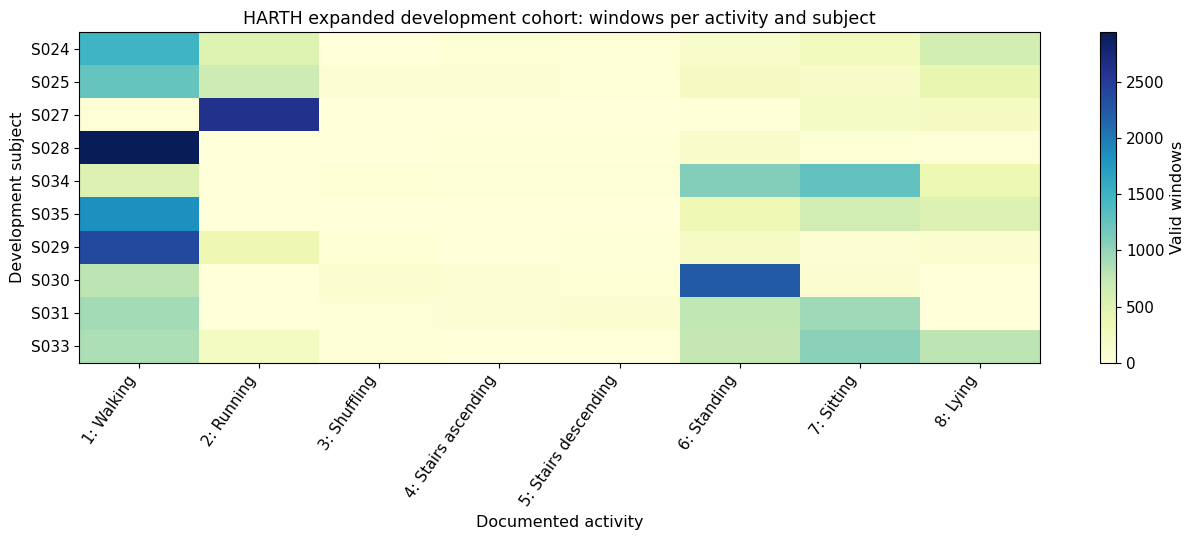

In [5]:
# ================ 04. Visualise Participant Activity Coverage ================
fig, ax = plt.subplots(figsize=(13, 5.5))

heat = ax.imshow(class_coverage.to_numpy(), aspect="auto", cmap="YlGnBu")
ax.set_xticks(np.arange(len(class_coverage.columns)), class_coverage.columns, rotation=55, ha="right")
ax.set_yticks(np.arange(len(class_coverage.index)), class_coverage.index)
ax.set(title="HARTH expanded development cohort: windows per activity and subject",
       xlabel="Documented activity", ylabel="Development subject")
fig.colorbar(heat, ax=ax, label="Valid windows")
fig.tight_layout()
save_figure(fig, output_dir / "07_development_activity_coverage.png")
plt.show()


**05. Run Five Subject-Disjoint Development Folds**

Each fold holds out two participants and trains on the other eight. Refit the classifiers and Train-only Logistic Regression scaler within each fold; reject folds without adequate training-class coverage. Balanced accuracy averages recall over classes present in each Validation fold; scikit-learn may warn when predictions include a class absent from its reference labels. Fixed-task Macro F1 uses the same eight predefined classes across all folds.

In [6]:
# ============== 05. Evaluate Five Participant-Disjoint CV Folds ==============
fold_results, subject_results, summary = evaluate_group_cross_validation(
    features=features.to_numpy(),
    labels=metadata["label"].to_numpy(),
    group_ids=metadata["subject_id"].to_numpy(),
    classes=TASK_CLASSES,
    n_splits=5,
    random_state=42,
)
display(summary.round(4))
display(fold_results[[
    "fold", "model", "train_subjects", "validation_subjects",
    "validation_classes_present", "macro_f1", "balanced_accuracy"
]].round(4))


Fold 1: Train=8 subjects, Validation=2 subjects
Dummy (most frequent): Validation Macro F1 = 0.0539
Logistic Regression: Validation Macro F1 = 0.6430
Random Forest: Validation Macro F1 = 0.7894
Fold 2: Train=8 subjects, Validation=2 subjects
Dummy (most frequent): Validation Macro F1 = 0.0551
Logistic Regression: Validation Macro F1 = 0.8370
Random Forest: Validation Macro F1 = 0.6588
Fold 3: Train=8 subjects, Validation=2 subjects
Dummy (most frequent): Validation Macro F1 = 0.0565


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Logistic Regression: Validation Macro F1 = 0.6351


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Random Forest: Validation Macro F1 = 0.7017
Fold 4: Train=8 subjects, Validation=2 subjects
Dummy (most frequent): Validation Macro F1 = 0.0654
Logistic Regression: Validation Macro F1 = 0.7139
Random Forest: Validation Macro F1 = 0.7368
Fold 5: Train=8 subjects, Validation=2 subjects
Dummy (most frequent): Validation Macro F1 = 0.1141
Logistic Regression: Validation Macro F1 = 0.7630
Random Forest: Validation Macro F1 = 0.7498


,model,fold_macro_f1_mean,fold_macro_f1_sd,fold_macro_f1_min,fold_macro_f1_max,subject_macro_f1_fixed_mean,subject_macro_f1_observed_mean
0,Random Forest,0.7273,0.0495,0.6588,0.7894,0.6138,0.7430
1,Logistic Regression,0.7184,0.0847,0.6351,0.8370,0.6130,0.7278
2,Dummy (most frequent),0.0690,0.0256,0.0539,0.1141,0.0666,0.0795


,fold,model,train_subjects,validation_subjects,validation_classes_present,macro_f1,balanced_accuracy
0,1,Random Forest,"S024, S025, S027, S028, S029, S030, S034, S035","S031, S033",8,0.7894,0.9147
1,1,Logistic Regression,"S024, S025, S027, S028, S029, S030, S034, S035","S031, S033",8,0.6430,0.8175
2,1,Dummy (most frequent),"S024, S025, S027, S028, S029, S030, S034, S035","S031, S033",8,0.0539,0.1250
3,2,Logistic Regression,"S024, S027, S028, S029, S030, S031, S033, S035","S025, S034",8,0.8370,0.8656
4,2,Random Forest,"S024, S027, S028, S029, S030, S031, S033, S035","S025, S034",8,0.6588,0.6505
5,2,Dummy (most frequent),"S024, S027, S028, S029, S030, S031, S033, S035","S025, S034",8,0.0551,0.1250
6,3,Random Forest,"S024, S025, S028, S029, S030, S031, S033, S034","S027, S035",6,0.7017,0.9704
7,3,Logistic Regression,"S024, S025, S028, S029, S030, S031, S033, S034","S027, S035",6,0.6351,0.9549
8,3,Dummy (most frequent),"S024, S025, S028, S029, S030, S031, S033, S034","S027, S035",6,0.0565,0.1667
9,4,Random Forest,"S025, S027, S028, S029, S031, S033, S034, S035","S024, S030",8,0.7368,0.6987


**06. Compare Fold and Participant Model Stability**

Inspect fixed-task Macro F1 by fold and by held-out participant, since aggregate means can hide differences between people.

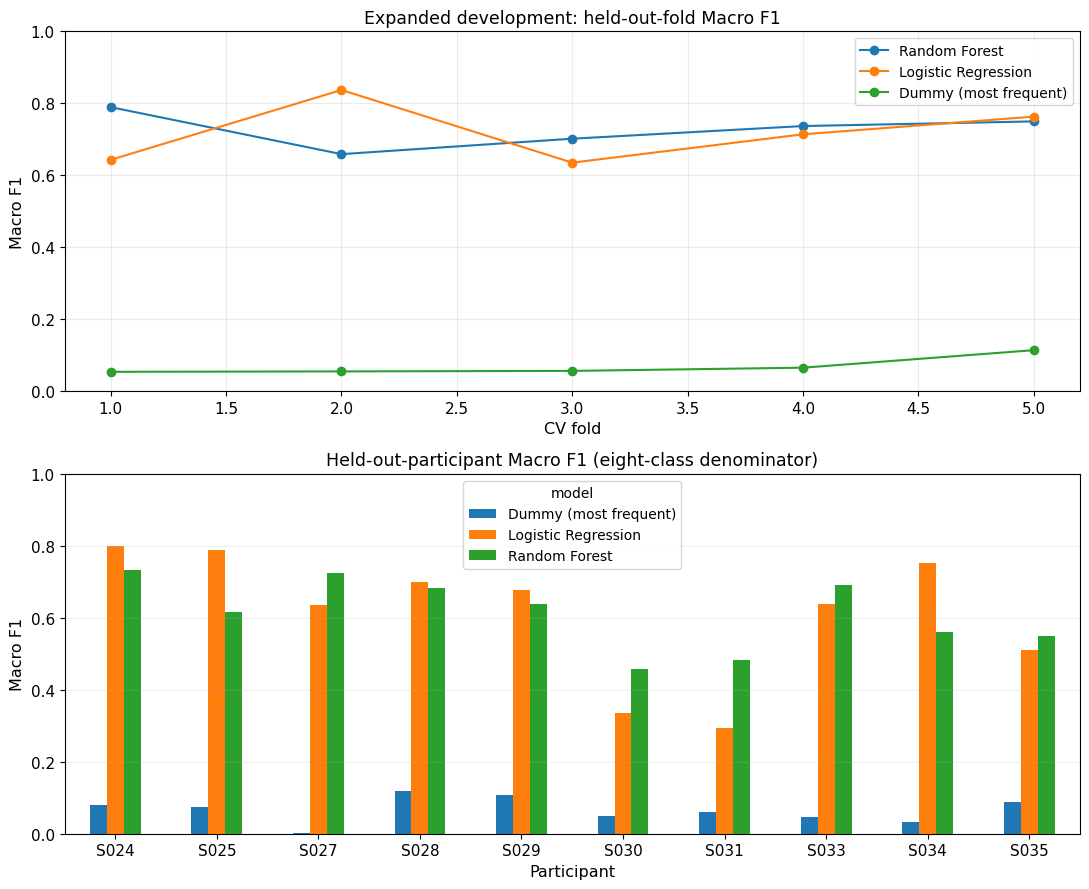

,fold,model,subject_id,windows,observed_classes,macro_f1_fixed_task,macro_f1_observed_classes
18,4,Dummy (most frequent),S024,3119,8,0.0809,0.0809
6,2,Dummy (most frequent),S025,2873,8,0.0754,0.0754
12,3,Dummy (most frequent),S027,3082,6,0.0028,0.0037
24,5,Dummy (most frequent),S028,3197,7,0.1197,0.1369
25,5,Dummy (most frequent),S029,3147,8,0.1078,0.1078
19,4,Dummy (most frequent),S030,3312,6,0.0480,0.0641
0,1,Dummy (most frequent),S031,2798,6,0.0616,0.0821
1,1,Dummy (most frequent),S033,3687,6,0.0477,0.0636
7,2,Dummy (most frequent),S034,3351,7,0.0334,0.0382
13,3,Dummy (most frequent),S035,3337,5,0.0888,0.1421


In [7]:
# ================ 06. Compare Fold and Subject-Level Results =================

# ----------------------- 1. Compare Fold-Level Scores ------------------------
fig, axes = plt.subplots(2, 1, figsize=(11, 9))

for name, part in fold_results.groupby("model", sort=False):
    part = part.sort_values("fold")
    axes[0].plot(part["fold"], part["macro_f1"], marker="o", label=name)

axes[0].set(title="Expanded development: held-out-fold Macro F1",
            xlabel="CV fold", ylabel="Macro F1", ylim=(0, 1))
axes[0].grid(alpha=0.25)
axes[0].legend()

# -------------------- 2. Compare Participant-Level Scores --------------------
per_subject = subject_results.pivot(
    index="subject_id", columns="model", values="macro_f1_fixed_task"
).sort_index()

per_subject.plot(kind="bar", ax=axes[1], rot=0)
axes[1].set(title="Held-out-participant Macro F1 (eight-class denominator)",
            xlabel="Participant", ylabel="Macro F1", ylim=(0, 1))
axes[1].grid(axis="y", alpha=0.2)
fig.tight_layout()
save_figure(fig, output_dir / "07_development_cv_performance.png")
plt.show()
display(subject_results.sort_values(["model", "subject_id"]).round(4))


**07. Research Quality Gate and Evidence Limitations**

Confirm ten-participant coverage, group separation and Test exclusion. These exploratory Development results precede the frozen 29-person protocol and do not establish external generalisation.


In [8]:
# =================== 07. Expanded Development Quality Gate ===================

# ----------------- 1. Verify Participant and Fold Integrity ------------------
reported_subjects = set(subject_results["subject_id"])

assert reported_subjects == set(DEVELOPMENT_SUBJECTS)
assert not (reported_subjects & RESERVED_TEST)
assert subject_results.groupby(["model", "subject_id"]).size().eq(1).all()
assert fold_results["macro_f1"].between(0, 1).all()
assert len(fold_results) == 5 * 3
assert np.isfinite(features.to_numpy()).all()

# ------------------------- 2. Quality Gate and Scope -------------------------
print("Expanded development grouped CV: PASSED")
print("Original final Test data loaded/evaluated: NO")
print("Clinical/generalisation claim: NOT SUPPORTED")

# ---------------------- 3. Save Development Research Outputs ----------------
overview.to_csv(output_dir / "07_development_cohort_summary.csv", index=False)
excluded.to_csv(output_dir / "07_excluded_source_codes.csv", index=False)
class_coverage.rename_axis("subject_id").reset_index().to_csv(
    output_dir / "07_subject_activity_coverage.csv", index=False
)
summary.to_csv(output_dir / "07_development_cv_model_summary.csv", index=False)
fold_results.to_csv(output_dir / "07_development_cv_fold_metrics.csv", index=False)
subject_results.to_csv(output_dir / "07_development_cv_participant_metrics.csv", index=False)
print("Saved expanded Development-only evidence in:", output_dir)

download_outputs_from_colab(folder="wearable_activity_recognition/output", stage="07")

Expanded development grouped CV: PASSED
Original final Test data loaded/evaluated: NO
Clinical/generalisation claim: NOT SUPPORTED
Saved expanded Development-only evidence in: /content/human-movement-intelligence/wearable_activity_recognition/output
------------------------------------------------------------------------
Notebook stage: 07
Files packaged: 8
  + 07_development_activity_coverage.png
  + 07_development_cohort_summary.csv
  + 07_development_cv_fold_metrics.csv
  + 07_development_cv_model_summary.csv
  + 07_development_cv_participant_metrics.csv
  + 07_development_cv_performance.png
  + 07_excluded_source_codes.csv
  + 07_subject_activity_coverage.csv
Download ZIP from Colab Contents: /content/wearable_activity_recognition_Stage_07_Outputs.zip
GitHub Commit/Push performed: NO
